In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
from Committor1D_helpers import *

fsz = 10 # font size
plt.rcParams.update({'font.size': fsz})


In [2]:
xmin = -1
xmax = 1
Nx = 256
x = np.linspace(xmin,xmax,Nx)

def V(x,par):
    aux = x**4 - 2*x**2 + 1
    pot = aux + par[0]*np.exp(-0.5*(x-par[1])**2/(par[2]**2))
    return pot

def Vder(x,par):
    aux = 4*x**3 - 4*x
    exp = np.exp(-0.5*(x-par[1])**2/(par[2]**2))
    der = aux - par[0]*(x-par[1])*exp/(par[2]**2)
    return der

p0min = 0
p0max = 5
p1min = -0.5
p1max = 0.5
p2min = 0.25
p2max = 0.7

Nsamples = 18
randperm1 = np.random.permutation(Nsamples)
randperm2 = np.random.permutation(Nsamples)
p0 = np.linspace(p0min,p0max,Nsamples)
p1 = np.linspace(p1min,p1max,Nsamples)
p2 = np.linspace(p2min,p2max,Nsamples)
p0 = np.reshape(p0,(Nsamples,1))
p1_randperm = np.reshape(p1[randperm1],(Nsamples,1))
p2_randperm = np.reshape(p2[randperm2],(Nsamples,1))
par_array = np.concatenate((p0,p1_randperm,p2_randperm),axis = 1)


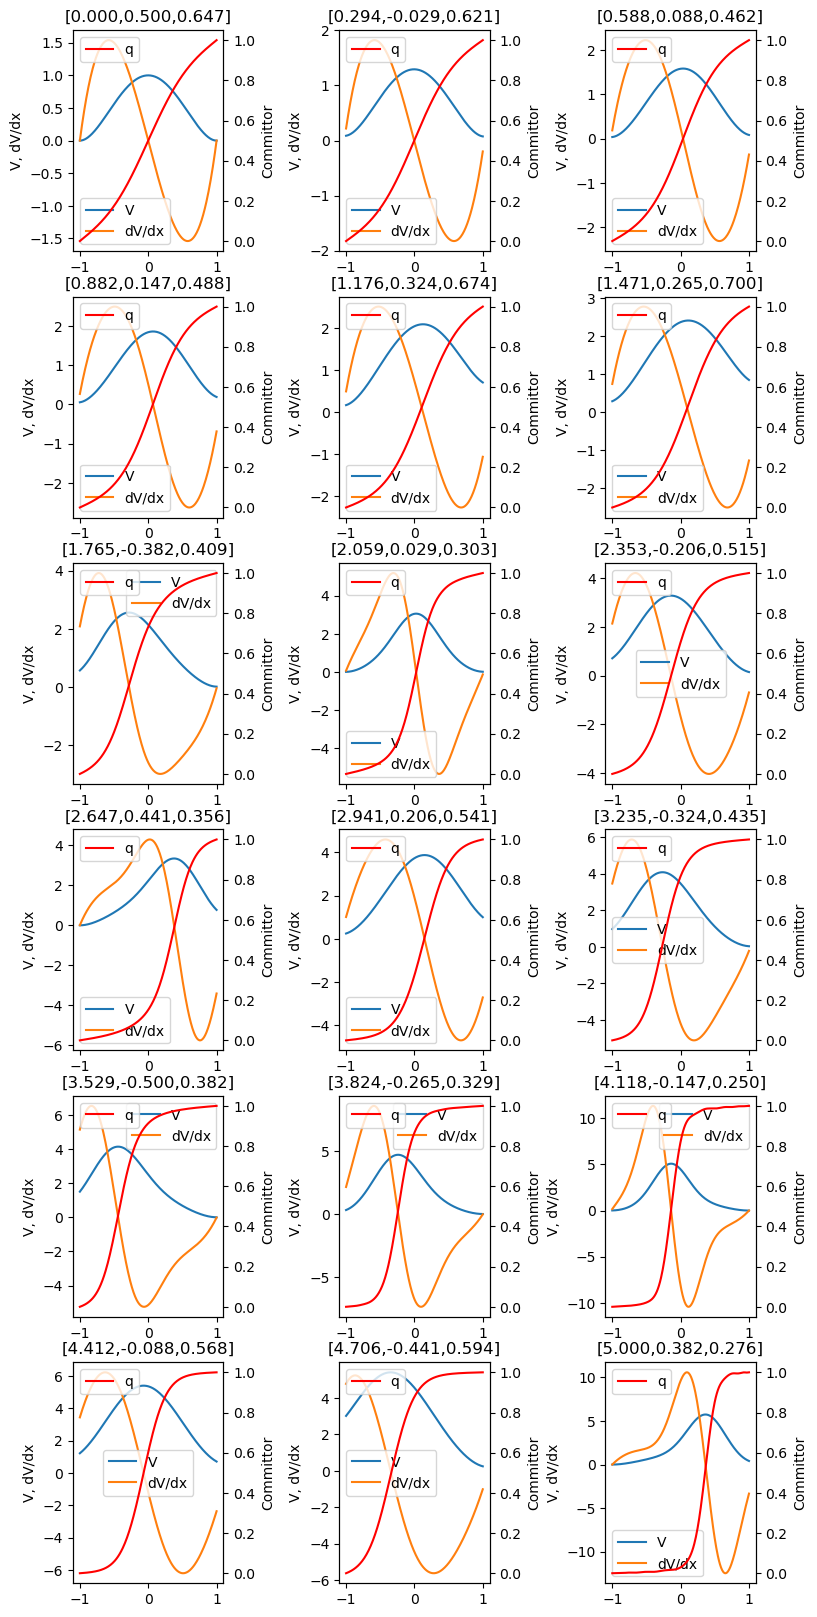

In [3]:
fig, ax = plt.subplots(6,3, figsize=(8,16))
# parameters for the Chebyshev spectral method
Ncheb = 20
shift = 0.5 * (xmin + xmax)
scale = 0.5 * (xmax - xmin)
# the inverse temperature
beta = 1

for j in range(Nsamples):
    # Generate u
    par = par_array[j,:]
    v = V(x,par)
    u = Vder(x,par)
    q = solve1Dcommittor(Ncheb,scale,shift,u,x,beta,x)
    row = j//3
    col = j%3
    ax[row,col].plot(x,v,label = "V")
    ax[row,col].plot(x,u,label = "dV/dx")
    ax2 = ax[row,col].twinx()
    ax2.plot(x,q,label = "q",color = 'red')
    ax[row,col].legend()
    ax2.set_xlabel("x")
    ax2.set_ylabel("Committor")
    ax2.legend()
    ax[row,col].set_ylabel("V, dV/dx")
    ax[row,col].set_title(f"[{par[0]:.3f},{par[1]:.3f},{par[2]:.3f}]")
plt.tight_layout(pad=0.1)    

In [4]:
# make data
Ndata = 1000
Nsamples = 18
randperm1 = np.random.permutation(Ndata)
randperm2 = np.random.permutation(Ndata)
p0 = np.linspace(p0min,p0max,Ndata)
p1 = np.linspace(p1min,p1max,Ndata)
p2 = np.linspace(p2min,p2max,Ndata)
p0 = np.reshape(p0,(Ndata,1))
p1_randperm = np.reshape(p1[randperm1],(Ndata,1))
p2_randperm = np.reshape(p2[randperm2],(Ndata,1))
par_array = np.concatenate((p0,p1_randperm,p2_randperm),axis = 1)
qdata = np.zeros((Ndata,np.size(x)))
udata = np.zeros_like(qdata)                 
for j in range(Ndata):
    # Generate u
    par = par_array[j,:]
    v = V(x,par)
    u = Vder(x,par)
    q = solve1Dcommittor(Ncheb,scale,shift,u,x,beta,x)
    qdata[j,:] = q
    udata[j,:] = u
    
np.savez("Comm_and_force_2params.npz",q = qdata,u = udata,x = x)